### Imports

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import time
import warnings
warnings.filterwarnings("ignore")

# Can change to cpu
device = "cuda:0"

### Cube function that the model uses

In [2]:
class Cube(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def forward(self, x):
        return x**3 / 6

### Model definition and parameter loading

In [3]:
# Change path to model ckpt
model = torch.load("variable_die_full.pt", weights_only=False).to(device)

Warpage has rigidbody transformation degree of freedom.  This function subtracts out the rigidbody deformation so the mean w, mean w_x, and mean w_y are 0 to make comparisons / cost calculations consistent

In [4]:
def subtract_plane_of_best_fit(w, x, y):
    """
    Subtracts the plane of best fit from w
    """
    A = torch.stack([x.ravel(), y.ravel(), torch.ones_like(x.ravel())], dim=1)  # (N, 3)
    coeff = torch.linalg.lstsq(A, w.ravel().unsqueeze(-1)).solution  # (3, 1)
    a, b, c = coeff[0], coeff[1], coeff[2]
    plane = a * x + b * y + c
    return w - plane

In [5]:
# Pick some bboxes, can be any amount

# bboxes = torch.tensor([
#     [-0.48, -0.42, -0.30, -0.18],
#     [-0.10, -0.47,  0.15, -0.30],
#     [ 0.22, -0.45,  0.48, -0.20],
#     [-0.45, -0.05, -0.20,  0.15],
#     [-0.05, -0.25,  0.10,  0.00],
#     [ 0.18, -0.05,  0.45,  0.18],
#     [-0.42,  0.22, -0.15,  0.45],
#     [-0.05,  0.28,  0.12,  0.48],
#     [ 0.18,  0.22,  0.48,  0.40],
#     [-0.10,  0.05,  0.10,  0.22],
# ])

# bboxes = torch.tensor([
#     [-0.4750, -0.4750, -0.2750, -0.2750],
#     [-0.4750, -0.2250, -0.2750, -0.0250],
#     [-0.4750,  0.0250, -0.2750,  0.2250],
#     [-0.4750,  0.2750, -0.2750,  0.4750],
#     [-0.2250, -0.4750, -0.0250, -0.2750],
#     [-0.2250, -0.2250, -0.0250, -0.0250],
#     [-0.2250,  0.0250, -0.0250,  0.2250],
#     [-0.2250,  0.2750, -0.0250,  0.4750],
#     [ 0.0250, -0.4750,  0.2250, -0.2750],
#     [ 0.0250, -0.2250,  0.2250, -0.0250]
# ])

bboxes = torch.tensor([
    [-0.4750, -0.4750, -0.2750, -0.2750],
    [-0.4750, -0.2250, -0.2750, -0.0250],
    [-0.4750,  0.0250, -0.2750,  0.2250],
    [-0.4750,  0.2750, -0.2750,  0.4750],
    [-0.2250, -0.4750, -0.0250, -0.2750],
])

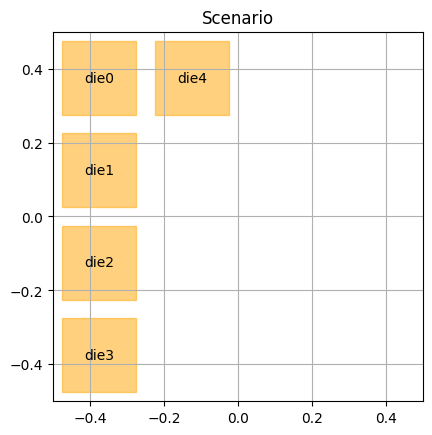

In [6]:
fig, ax = plt.subplots()
plt.xlim(-.5, .5)
plt.ylim(-.5, .5)

for i, bbox in enumerate(bboxes):
    xmin, ymin, xmax, ymax = bbox
    w, h = xmax - xmin, ymax - ymin

    # Flip y so it matches other images
    rect = patches.Rectangle((xmin, -h-ymin), w, h, linewidth=1, edgecolor='orange', facecolor='orange', alpha=0.5)
    ax.add_patch(rect)
    ax.text((xmin+xmax)/2, -(ymin+ymax)/2, f'die{i}', ha='center', va='center')
ax.set_aspect('equal')
ax.grid(True)

plt.title("Scenario")

plt.show()

### Function that takes bounding boxes and predicts the warpage

In [7]:
# Predicts warpage for a given set of die bboxes - assumes center of package is 0, 0
def predict_warpage(bboxes, substrate_length, grid_size=128):
    
    # Currently works on (-.5, .5) square
    x_ = torch.linspace(-.5, .5, grid_size)
    y_ = torch.linspace(-.5, .5, grid_size)
    x, y = torch.meshgrid(x_, y_, indexing='ij')
    x, y = x.flatten().to(device), y.flatten().to(device)
    points = torch.stack([x, y], dim=-1)

    bboxes = torch.cat([bboxes, torch.zeros(20-bboxes.shape[0], 4)], dim=0) / substrate_length

    bboxes_rep = bboxes.to(device).unsqueeze(0).repeat_interleave(grid_size**2, 0)
    w_pred = model(torch.cat([points, bboxes_rep.reshape(grid_size**2, -1)], dim=-1)).squeeze(-1)
    w_pred = subtract_plane_of_best_fit(w_pred, x, y)

    return w_pred.reshape(grid_size, grid_size) * substrate_length**2

In [8]:
# Example of length scaling

substrate_length = 150
bboxes = torch.tensor([
    [-4.750, -4.750, -2.750, -2.750],
    [-4.750, -2.250, -2.750, -0.250],
    [-4.750,  0.250, -2.750,  2.250],
    [-4.750,  2.750, -2.750,  4.750],
    [-2.250, -4.750, -0.250, -2.750],
])

with torch.no_grad():
    w_pred = predict_warpage(bboxes, substrate_length)

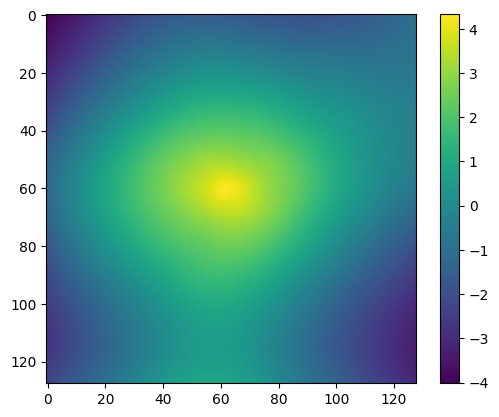

In [9]:
plt.imshow(w_pred.cpu())
plt.colorbar()
plt.show()

### Time how long to predict

In [10]:
t0 = time.time()

for _ in range(100):
    with torch.no_grad():
        w_pred = predict_warpage(bboxes, substrate_length)

print(f"Time to predict: {(time.time() - t0)/100:.4f}")

Time to predict: 0.0104
